In [1]:
import h5py, os, cv2, matplotlib
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# define variables 
fileDirectory = 'C:\\Users\\Admin\\UniBE\\data\\040725_Organoid' # 150525_530_15_1a_DRC470_02
fileName = '040725_Organoid1_DRC505_01_HT-100.bxr' # '150525_530_15_1a_DRC470_02.bxr'
wellID = 'Well_A1' # identifier of chip well to be analysed 

# open the BXR file 
file = h5py.File(os.path.join(fileDirectory,fileName), 'r')

In [3]:
# collect experiment information 
minDigitalValue = file.attrs['MinDigitalValue'] 
maxDigitalValue = file.attrs['MaxDigitalValue'] 
minAnalogValue = file.attrs['MinAnalogValue'] 
maxAnalogValue = file.attrs['MaxAnalogValue'] 
dacFactor = (maxAnalogValue - minAnalogValue) / (maxDigitalValue - minDigitalValue) 
offsetValue = minAnalogValue - dacFactor * minDigitalValue 
samplingRate = file.attrs['SamplingRate']
chIdxs = np.array(file[wellID + '/StoredChIdxs']) 

In [4]:
# collect the required spike data 
spikeDataTimestamps = file[wellID + '/SpikeTimes'][:] 
spikeDataChIdxs = file[wellID + '/SpikeChIdxs'][:]

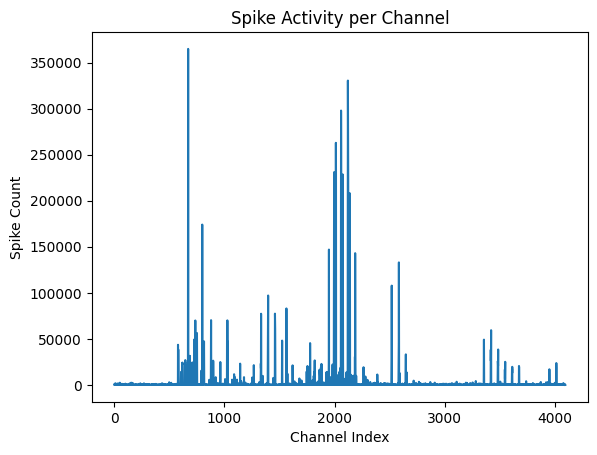

In [5]:
# Count spikes per channel
unique_channels, spike_counts = np.unique(spikeDataChIdxs, return_counts=True)
# Plot
plt.plot(unique_channels, spike_counts)
plt.xlabel('Channel Index')
plt.ylabel('Spike Count')
plt.title('Spike Activity per Channel')
plt.show()

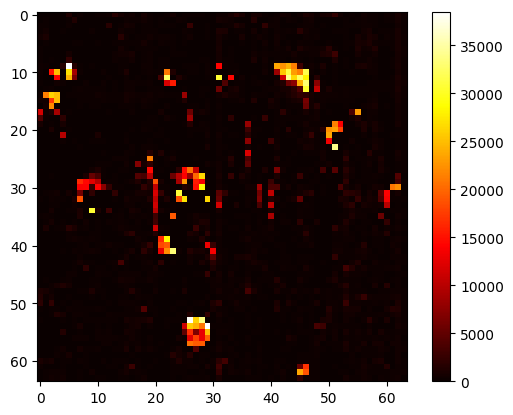

In [6]:
from collections import Counter
counts = dict(Counter(spikeDataChIdxs))

counts_array = np.zeros((64, 64))

for key in counts.keys():
    r, c = key//64, key%64
    if counts[key] > 40000:
        counts_array[r][c] = 0
    else:
        counts_array[r][c] = counts[key]

dpi = 17.5

fig = plt.Figure(figsize=(64/dpi,64/dpi), dpi=dpi)
plt.imshow(counts_array, cmap='hot', interpolation='none')
plt.axis('off')
plt.savefig(os.path.join(fileDirectory, "heatmap.png"), bbox_inches='tight', pad_inches=0, dpi=dpi)

plt.axis('on')
plt.colorbar()
plt.show()

In [7]:
from PIL import Image, ExifTags
%matplotlib Tk
# Open image with PIL and correct orientation
image_path = "C:\\Users\\Admin\\UniBE\\data\\040725_Organoid\\IMG_3840.jpg"
img = Image.open(image_path)
width, height = img.size

if width > 1500 or height > 1500:
    img.thumbnail((1000, 1000), Image.Resampling.LANCZOS)

print(img.size[0], img.size[1])

# Handle EXIF orientation
try:
    for orientation in ExifTags.TAGS.keys():
        if ExifTags.TAGS[orientation] == 'Orientation':
            break

    exif = img._getexif()
    if exif is not None:
        orientation_value = exif.get(orientation, None)

        if orientation_value == 3:
            img = img.rotate(180, expand=True)
        elif orientation_value == 6:
            img = img.rotate(270, expand=True)
        elif orientation_value == 8:
            img = img.rotate(90, expand=True)
except (AttributeError, KeyError, IndexError):
    # If image has no EXIF data or cannot read orientation
    pass

# Convert to NumPy array and show
img = plt.imread(image_path) if isinstance(img, str) else np.array(img)

plt.imshow(img)
points = plt.ginput(4)
print(points)
plt.close()

889 1000
[(np.float64(63.04761904761904), np.float64(92.5735930735932)), (np.float64(844.4329004329006), np.float64(83.91558441558436)), (np.float64(863.9134199134201), np.float64(871.7943722943724)), (np.float64(54.389610389610425), np.float64(871.7943722943724))]


In [ ]:
%matplotlib Tk
img = plt.imread("C:\\Users\\Admin\\UniBE\\data\\040725_Organoid\\IMG_3840.jpg")
print(img)
plt.imshow(img)
points = plt.ginput(4)  # Click 4 points on the image
print(points)
plt.close()

[[[ 90   0   9]
  [ 91   1  10]
  [ 91   1  10]
  ...
  [ 74   2   6]
  [ 74   2   6]
  [ 74   2   6]]

 [[ 90   0   9]
  [ 91   1  10]
  [ 91   1  10]
  ...
  [ 74   2   6]
  [ 74   2   6]
  [ 74   2   6]]

 [[ 90   0   9]
  [ 91   1  10]
  [ 91   1  10]
  ...
  [ 74   2   6]
  [ 74   2   6]
  [ 74   2   6]]

 ...

 [[118   1   9]
  [118   1   9]
  [118   1   9]
  ...
  [128   0  10]
  [126   0  10]
  [128   1  12]]

 [[122   5  13]
  [122   5  13]
  [122   5  13]
  ...
  [128   0  10]
  [126   0  10]
  [128   1  12]]

 [[126   9  17]
  [125   8  16]
  [125   8  16]
  ...
  [128   0  10]
  [126   0  10]
  [128   1  12]]]
[]


In [8]:
heatmap = cv2.imread("C:\\Users\\Admin\\UniBE\\data\\040725_Organoid\\heatmap.png") 
# plt.imread --> 4-channel images (R, G, B, alpha) so use cv2.imread instead for 3-channel images

# Points on the heatmap
src_pts = np.array([
    [0, 0],      # top-left of heatmap
    [63, 0],     # top-right
    [63, 63],    # bottom-rigt
    [0, 63]      # bottom-left
], dtype=np.float32)

# Corresponding points on the zoomed-out image
dst_pts = np.array(points, dtype=np.float32)

# Transform
matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)

# wrap heatmap to image shape
height, width, _ = img.shape
print(height, width)
wrapped_heatmap = cv2.warpPerspective(heatmap, matrix, (width, height))

# Normalise and colour heatmap
heatmap_norm = cv2.normalize(wrapped_heatmap, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
heatmap_colour = cv2.applyColorMap(heatmap_norm, cv2.COLORMAP_JET)

# Overlay
alpha = 0.5
overlay = cv2.addWeighted(img, 1-alpha, heatmap_colour, alpha, 0)

# Display
cv2.imshow("Overlay", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
cv2.waitKey(0)
cv2.destroyAllWindows()

1000 889


In [ ]:
# Contour detection
img_copy = img.copy()
grey = cv2.cvtColor(img_copy, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(grey, (5, 5), 0)

_, thresholded = cv2.threshold(blurred, 50, 255, cv2.THRESH_BINARY)
    
# rectangular kernel (5x5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))    # General kernel size
cleaned = cv2.morphologyEx(thresholded, cv2.MORPH_OPEN, kernel)  # Remove noise
closed = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)      # Fill gaps

cv2.imshow("Thresholded", thresholded)
cv2.waitKey(0)  # Wait for any key press to close the window
cv2.destroyAllWindows()

# Find contours
contours, _ = cv2.findContours(thresholded, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

for contour in contours:
    area = cv2.contourArea(contour)  
    if area > 10000:
        print(area)
        best_contour = contour

cv2.drawContours(overlay, best_contour, -1, (0, 255, 0), 2)
cv2.imshow("Contours", cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
cv2.imwrite('contours.png', cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))
cv2.waitKey(0)
cv2.destroyAllWindows()

# for point in best_contour:
#         x, y = point[0]  # point is [[x, y]]
#         print(f"({x}, {y})")


2.0
9.5
16.5
38.5
73.0
10.0
6.0
3.5
0.0
15.5
1.5
4.5
0.0
5.5
1.5
10.5
9.5
0.0
8.5
21.5
0.5
0.0
2.0
2.0
3.5
6.0
0.0
0.0
13.5
2.0
0.0
2.5
1.0
1.0
2.0
13.5
4.0
35.5
7.5
1.5
10.0
0.0
2.0
7.0
4.5
44.0
0.0
0.0
0.5
22.5
0.0
0.0
2.0
3.0
0.0
3.0
1.5
5.0
4.0
0.0
2.0
0.0
11034.0
11034.0
18.0
3.5
1.0
4.0
11.5
17.5
1.0
0.5
0.0
0.0
0.0
2.5
12674.5
12674.5
5.0
0.0
4.5
16.0
0.5
16.5
0.0
3.5
5.5
0.0
1.0
2.0
8.5
32.5
5.0
6.0
0.0
5.0
8.5
11.0
12.0
34.5
0.0
0.0
1.5
3.0
1.0
0.0
0.0
0.5
0.0
10481.0
10481.0
0.0
0.0
1.0
1.5
1.5
0.0
4.0
0.5
0.0
0.0
3.5
0.5
20.0
2.5
21.5
2.5
0.5
267.5
3.0
2.0
0.0
0.0
0.5
3.5
0.0
9476.0
39.0
0.0
4.0
2.0
1.5
0.0
1.5
9.0
8.5
7.0
0.0
6.0
0.0
1.0
12.5
4.5
2.5
0.0


In [ ]:
# Transform
matrix_inv = cv2.getPerspectiveTransform(dst_pts, src_pts)

contour = best_contour.astype('float32') # Ensure type is float32
transformed_contour = cv2.perspectiveTransform(contour, matrix_inv)
cv2.drawContours(heatmap, [transformed_contour.astype(int)], 0, (0, 255, 0), thickness=cv2.FILLED)
cv2.imwrite('image1.png', heatmap)
cv2.destroyAllWindows()

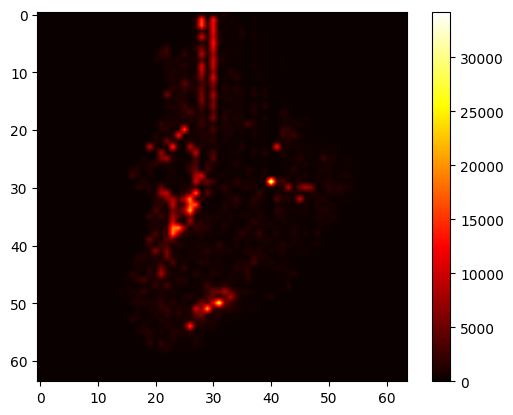

In [ ]:
%matplotlib inline
mask = np.all(heatmap == [0, 255, 0], axis=-1)  
coords = np.column_stack(np.where(mask))
cleaned_heatmap = np.zeros((64, 64))
channels = []
for point in coords:
    x, y = point
    cleaned_heatmap[x][y] = counts_array[x][y]
    channels.append(64*x+y)
    # coordinate conventions differ between image and heatmaps (i.e., x and y are flipped)

fig = plt.Figure()
plt.imshow(cleaned_heatmap, cmap='hot', interpolation='bilinear')
plt.axis('on')
plt.colorbar()
plt.show()

In [ ]:
mask = np.isin(spikeDataChIdxs, channels)
spikeDataChIdxs[np.where(~mask)] = 0

Spike sorting

In [ ]:
waveformLength = file[wellID + '/SpikeForms'].attrs['Wavelength'] 
print(waveformLength)
spikeDataWaveforms = file[wellID + '/SpikeForms'][:] 

31


In [ ]:
waveformData = [] 
chIdx = 96
for idx, ch in enumerate(spikeDataChIdxs): 
    if ch == chIdx: 
        waveformData.append(spikeDataWaveforms[idx*waveformLength:idx*waveformLength+waveformLength]) 

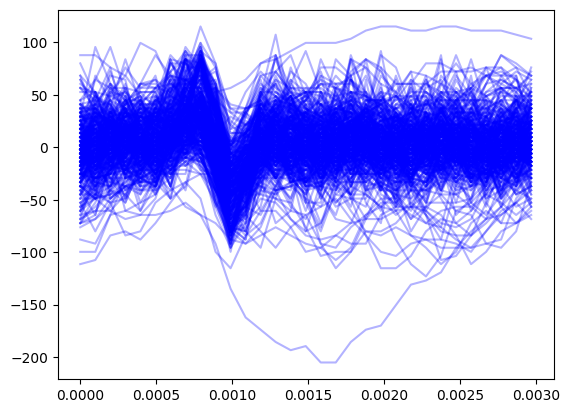

In [ ]:
# %matplotlib inline
x = np.arange(0, waveformLength, 1) / samplingRate 
for waveform in waveformData: 
    # convert the waveform to analog 
    y = offsetValue + dacFactor * waveform
    plt.plot(x, y, color='blue', alpha=0.3)

PCA

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pcs = pca.fit_transform(waveformData)
X = pcs[:, :2]

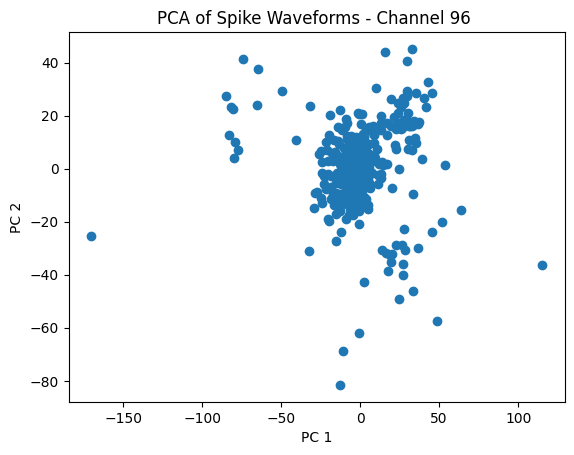

In [ ]:
plt.figure()
plt.scatter(pcs[:, 0], pcs[:, 1])
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title(f'PCA of Spike Waveforms - Channel {chIdx} ')
plt.show()

Mean-shift Clustering

In [ ]:
from sklearn.cluster import MeanShift, estimate_bandwidth

bandwidth = estimate_bandwidth(X)
ms = MeanShift(bandwidth=bandwidth).fit(X)
labels = ms.labels_
cluster_centers = ms.cluster_centers_

labels_unique = np.unique(labels)
n_clusters_ = len(labels_unique)

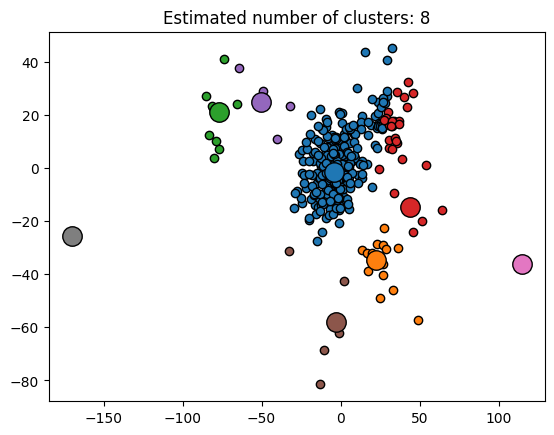

In [ ]:
plt.figure(1)
colors = matplotlib.cm.tab10(range(n_clusters_))

for k, col in zip(range(n_clusters_), colors):
    my_members = labels == k
    cluster_center = cluster_centers[k]
    
    # Plot cluster members
    plt.plot(
        X[my_members, 0],
        X[my_members, 1],
        'o',
        markerfacecolor=col,
        markeredgecolor='k',
        markersize=6,
    )
    
    # Plot cluster center
    plt.plot(
        cluster_center[0],
        cluster_center[1],
        'o',
        markerfacecolor=col,
        markeredgecolor='k',
        markersize=14,
    )

plt.title("Estimated number of clusters: %d" % n_clusters_)
plt.show()


In [ ]:
# add point and waveform selection